In [2]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [3]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [4]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


# Random Forest

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:15<00:00,  2.72it/s]


Epoch [1/50] Train Loss: 0.5092 (CE: 0.6577, Dice: 0.3607), Train Acc: 0.6835 | Val Loss: 0.5012 (CE: 0.6374, Dice: 0.3651), Val Acc: 0.6396
  -> Saving best model (Val Accuracy: 0.6396)


100%|██████████| 43/43 [00:15<00:00,  2.71it/s]


Epoch [2/50] Train Loss: 0.4335 (CE: 0.5274, Dice: 0.3397), Train Acc: 0.7110 | Val Loss: 0.4684 (CE: 0.5546, Dice: 0.3821), Val Acc: 0.6687
  -> Saving best model (Val Accuracy: 0.6687)


100%|██████████| 43/43 [00:15<00:00,  2.72it/s]


...

Epoch [16/50] Train Loss: 0.3906 (CE: 0.4706, Dice: 0.3106), Train Acc: 0.7368 | Val Loss: 0.5512 (CE: 0.6693, Dice: 0.4331), Val Acc: 0.6417
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:15<00:00,  2.76it/s]


Epoch [17/50] Train Loss: 0.3828 (CE: 0.4608, Dice: 0.3048), Train Acc: 0.7423 | Val Loss: 0.4628 (CE: 0.5677, Dice: 0.3579), Val Acc: 0.6458
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 17. Best Val Accuracy: 0.7375


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



Extracting ResNet18 features...
Feature shape: (2720, 512)

Random Forest Validation Accuracy: 0.6979
Random Forest Test Accuracy: 0.9060

Random Forest Test Precision: 0.9054
Random Forest Test Recall:    0.9060
Random Forest Test F1-score:  0.9056

Random Forest Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.93      0.94      0.93      1052
  Appears normal       0.84      0.82      0.83       416

        accuracy                           0.91      1468
       macro avg       0.89      0.88      0.88      1468
    weighted avg       0.91      0.91      0.91      1468



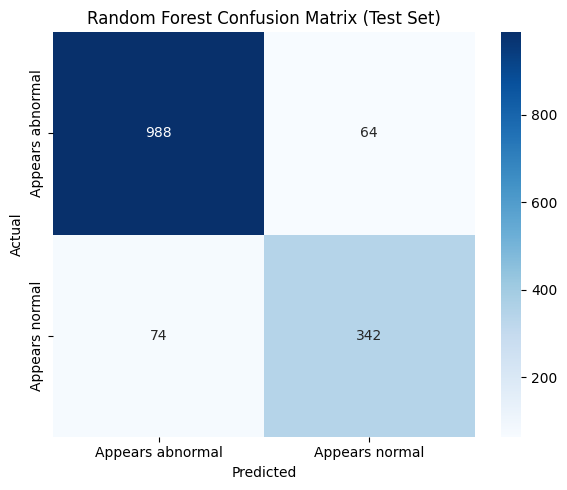


Final ResNet18 Test Loss: 0.4316 (CE: 0.3354, Dice: 0.5279), Final ResNet18 Test Accuracy: 0.8842

ResNet18 Test Precision (weighted): 0.8874
ResNet18 Test Recall (weighted):    0.8842
ResNet18 Test F1-score (weighted):  0.8776

ResNet18 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.88      0.98      0.92      1052
  Appears normal       0.92      0.65      0.76       416

        accuracy                           0.88      1468
       macro avg       0.90      0.81      0.84      1468
    weighted avg       0.89      0.88      0.88      1468



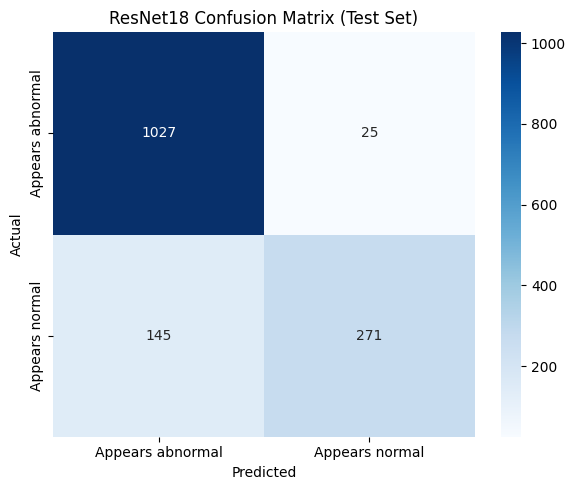

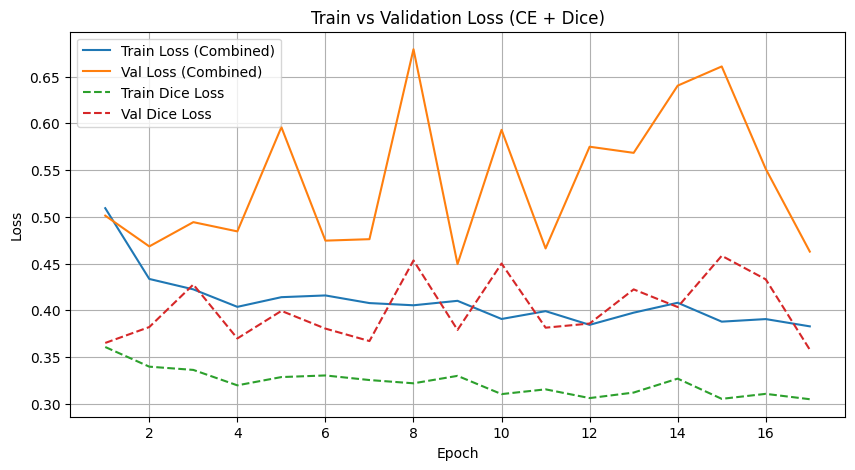

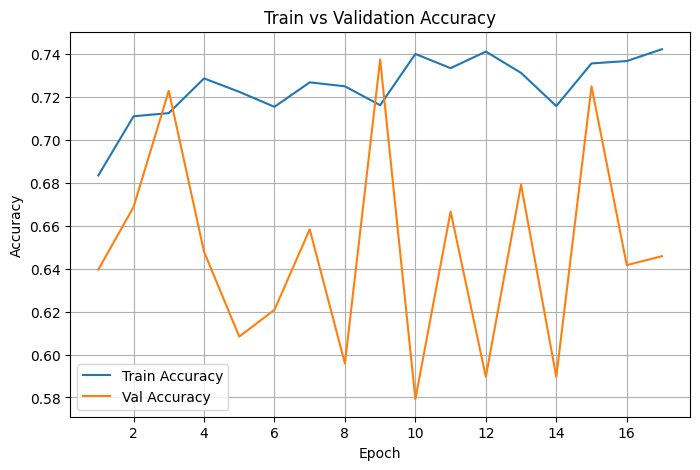


================ FINAL SUMMARY ================
ResNet18 Best Val Accuracy: 0.7375
ResNet18 Test Accuracy: 0.8842
ResNet18 Test Precision: 0.8874
ResNet18 Test Recall: 0.8842
ResNet18 Test F1-score: 0.8776
ResNet18 Test Dice Loss: 0.5279

--------------- Random Forest ----------------
Random Forest Val Accuracy: 0.6979
Random Forest Test Accuracy: 0.9060
Random Forest Test Precision: 0.9054
Random Forest Test Recall: 0.9060
Random Forest Test F1-score: 0.9056


In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import RandomForestClassifier
import seaborn as sns


# ============================================================
# Device configuration
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================

train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# Image transformations
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# Split train_dataset into train_subset + val_subset (85/15)
# ============================================================

val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Count the number of samples per class
# ============================================================

train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(train_targets)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================================
# Load pre-trained ResNet18 model
# ============================================================

resnet = models.resnet18(pretrained=True)

num_classes = len(train_dataset.classes)

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    num_classes
)

resnet = resnet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection
            + self.smooth
        ) / (
            union
            + self.smooth
        )

        dice_loss = (
            1. - dice_score.mean()
        )

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight


    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


optimizer = optim.Adam(
    resnet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate the model
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(
    model,
    loader
):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Resnet18_pcos.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# ResNet18 Training
# ============================================================

for epoch in range(max_epochs):

    resnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()


    train_accuracy = (
        correct_train / total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss / n_batches
    )

    train_ce = (
        running_ce / n_batches
    )

    train_dice = (
        running_dice / n_batches
    )


    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        resnet,
        val_loader
    )


    train_losses.append(
        train_loss
    )

    train_accs.append(
        train_accuracy
    )

    val_losses.append(
        val_loss
    )

    val_accs.append(
        val_accuracy
    )

    train_ce_losses.append(
        train_ce
    )

    train_dice_losses.append(
        train_dice
    )

    val_ce_losses.append(
        val_ce
    )

    val_dice_losses.append(
        val_dice
    )


    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # ========================================================
    # Early stopping logic
    # ========================================================

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            resnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best ResNet18 model
# ============================================================

best_resnet_model = models.resnet18(
    pretrained=False
)

best_resnet_model.fc = nn.Linear(
    best_resnet_model.fc.in_features,
    num_classes
)

best_resnet_model = best_resnet_model.to(device)

best_resnet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# RANDOM FOREST
# ResNet18 feature extraction + Random Forest
# ============================================================

def extract_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # ResNet18 feature extractor
            x = model.conv1(images)
            x = model.bn1(x)
            x = model.relu(x)
            x = model.maxpool(x)

            x = model.layer1(x)
            x = model.layer2(x)
            x = model.layer3(x)
            x = model.layer4(x)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten features
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print(
    "\nExtracting ResNet18 features..."
)


train_features, train_labels = extract_features(
    best_resnet_model,
    train_loader
)


val_features, val_labels = extract_features(
    best_resnet_model,
    val_loader
)


test_features, test_labels = extract_features(
    best_resnet_model,
    test_loader
)


print(
    "Feature shape:",
    train_features.shape
)


# ============================================================
# Train Random Forest
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)


rf_model.fit(
    train_features,
    train_labels
)


# ============================================================
# Random Forest Validation
# ============================================================

rf_val_preds = rf_model.predict(
    val_features
)


rf_val_accuracy = np.mean(
    rf_val_preds == val_labels
)


print(
    f"\nRandom Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)


# ============================================================
# Random Forest Test
# ============================================================

rf_test_preds = rf_model.predict(
    test_features
)


rf_test_accuracy = np.mean(
    rf_test_preds == test_labels
)


print(
    f"Random Forest Test Accuracy: "
    f"{rf_test_accuracy:.4f}"
)


# ============================================================
# Random Forest Metrics
# ============================================================

class_names = train_dataset.classes


rf_precision = precision_score(
    test_labels,
    rf_test_preds,
    average='weighted'
)


rf_recall = recall_score(
    test_labels,
    rf_test_preds,
    average='weighted'
)


rf_f1 = f1_score(
    test_labels,
    rf_test_preds,
    average='weighted'
)


print(
    f"\nRandom Forest Test Precision: "
    f"{rf_precision:.4f}"
)


print(
    f"Random Forest Test Recall:    "
    f"{rf_recall:.4f}"
)


print(
    f"Random Forest Test F1-score:  "
    f"{rf_f1:.4f}"
)


# ============================================================
# Random Forest Classification Report
# ============================================================

print(
    "\nRandom Forest Per-class report:"
)


print(
    classification_report(
        test_labels,
        rf_test_preds,
        target_names=class_names
    )
)


# ============================================================
# Random Forest Confusion Matrix
# ============================================================

rf_cm = confusion_matrix(
    test_labels,
    rf_test_preds
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel('Predicted')

plt.ylabel('Actual')


plt.title(
    'Random Forest Confusion Matrix (Test Set)'
)


plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL RESNET18 TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_resnet_model,
    test_loader
)


print(
    f'\nFinal ResNet18 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final ResNet18 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# ResNet18 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_resnet_model,
    test_loader
)


class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)


recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)


f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)


print(
    f'\nResNet18 Test Precision (weighted): '
    f'{precision:.4f}'
)


print(
    f'ResNet18 Test Recall (weighted):    '
    f'{recall:.4f}'
)


print(
    f'ResNet18 Test F1-score (weighted):  '
    f'{f1:.4f}'
)


# ============================================================
# ResNet18 Classification Report
# ============================================================

print(
    '\nResNet18 Per-class report:'
)


print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# ResNet18 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel('Predicted')

plt.ylabel('Actual')


plt.title(
    'ResNet18 Confusion Matrix (Test Set)'
)


plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)


plt.figure(
    figsize=(10, 5)
)


plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)


plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)


plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)


plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)


plt.xlabel('Epoch')

plt.ylabel('Loss')


plt.title(
    'Train vs Validation Loss (CE + Dice)'
)


plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)


plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)


plt.xlabel('Epoch')

plt.ylabel('Accuracy')


plt.title(
    'Train vs Validation Accuracy'
)


plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)


print(
    f'ResNet18 Best Val Accuracy: '
    f'{best_accuracy:.4f}'
)


print(
    f'ResNet18 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


print(
    f'ResNet18 Test Precision: '
    f'{precision:.4f}'
)


print(
    f'ResNet18 Test Recall: '
    f'{recall:.4f}'
)


print(
    f'ResNet18 Test F1-score: '
    f'{f1:.4f}'
)


print(
    f'ResNet18 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n--------------- Random Forest ----------------'
)


print(
    f'Random Forest Val Accuracy: '
    f'{rf_val_accuracy:.4f}'
)


print(
    f'Random Forest Test Accuracy: '
    f'{rf_test_accuracy:.4f}'
)


print(
    f'Random Forest Test Precision: '
    f'{rf_precision:.4f}'
)


print(
    f'Random Forest Test Recall: '
    f'{rf_recall:.4f}'
)


print(
    f'Random Forest Test F1-score: '
    f'{rf_f1:.4f}'
)

# KNN

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:15<00:00,  2.73it/s]


Epoch [1/50] Train Loss: 0.5033 (CE: 0.6329, Dice: 0.3736), Train Acc: 0.6687 | Val Loss: 0.6810 (CE: 0.9027, Dice: 0.4594), Val Acc: 0.6104
  -> Saving best model (Val Accuracy: 0.6104)


100%|██████████| 43/43 [00:15<00:00,  2.74it/s]


Epoch [2/50] Train Loss: 0.4462 (CE: 0.5357, Dice: 0.3566), Train Acc: 0.6879 | Val Loss: 0.5011 (CE: 0.5821, Dice: 0.4200), Val Acc: 0.5833
  -> No improvement for 1/8 epochs


100%|██████████| 43/43 [00:15<00:00,  2.76it/s]


...

Epoch [24/50] Train Loss: 0.3957 (CE: 0.4765, Dice: 0.3149), Train Acc: 0.7257 | Val Loss: 0.4664 (CE: 0.5508, Dice: 0.3819), Val Acc: 0.6479
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:15<00:00,  2.69it/s]


Epoch [25/50] Train Loss: 0.3732 (CE: 0.4520, Dice: 0.2943), Train Acc: 0.7518 | Val Loss: 0.8471 (CE: 1.1759, Dice: 0.5183), Val Acc: 0.4146
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 25. Best Val Accuracy: 0.7979

Extracting ResNet18 features...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Feature shape: (2720, 512)

KNN Validation Accuracy: 0.7083
KNN Test Accuracy: 0.8890

KNN Test Precision: 0.8870
KNN Test Recall:    0.8890
KNN Test F1-score:  0.8871

KNN Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.91      0.94      0.92      1052
  Appears normal       0.84      0.75      0.79       416

        accuracy                           0.89      1468
       macro avg       0.87      0.85      0.86      1468
    weighted avg       0.89      0.89      0.89      1468



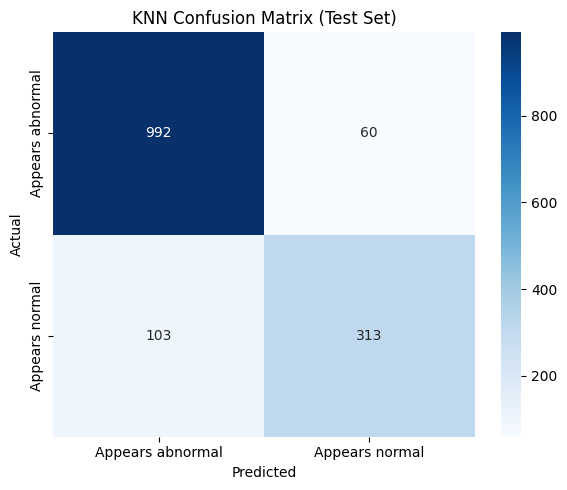


Final ResNet18 Test Loss: 0.5914 (CE: 0.6351, Dice: 0.5478), Final ResNet18 Test Accuracy: 0.8202

ResNet18 Test Precision (weighted): 0.8431
ResNet18 Test Recall (weighted):    0.8202
ResNet18 Test F1-score (weighted):  0.7922

ResNet18 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.80      0.99      0.89      1052
  Appears normal       0.94      0.39      0.55       416

        accuracy                           0.82      1468
       macro avg       0.87      0.69      0.72      1468
    weighted avg       0.84      0.82      0.79      1468



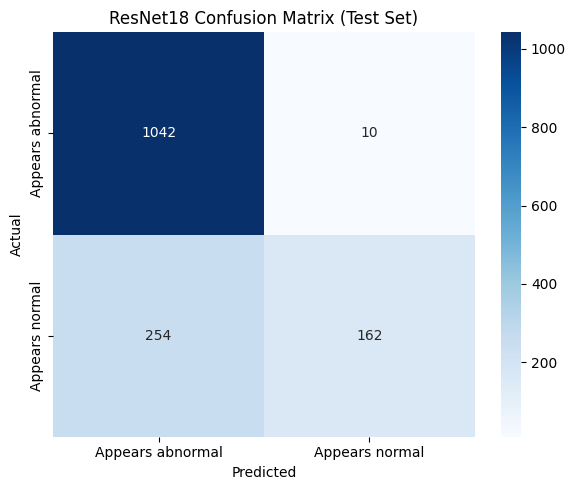

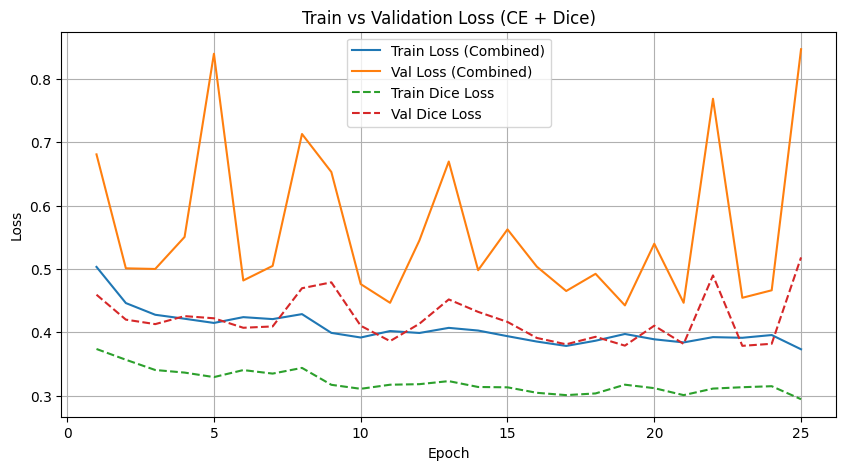

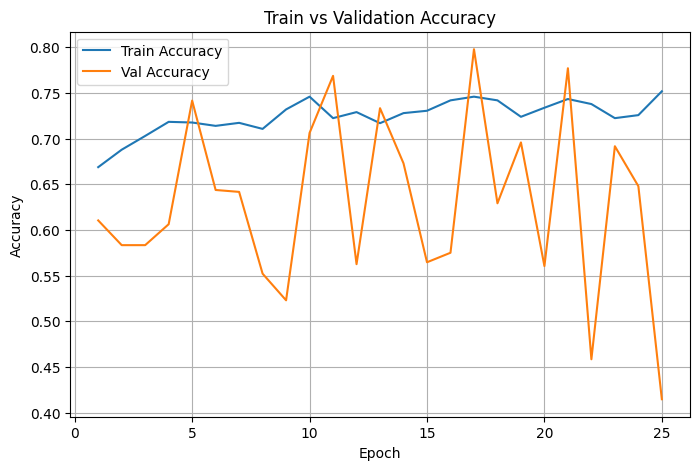


================ FINAL SUMMARY ================
ResNet18 Best Val Accuracy: 0.7979
ResNet18 Test Accuracy: 0.8202
ResNet18 Test Precision: 0.8431
ResNet18 Test Recall: 0.8202
ResNet18 Test F1-score: 0.7922
ResNet18 Test Dice Loss: 0.5478

--------------- KNN ----------------
KNN Val Accuracy: 0.7083
KNN Test Accuracy: 0.8890
KNN Test Precision: 0.8870
KNN Test Recall: 0.8890
KNN Test F1-score: 0.8871


In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns


# ============================================================
# Device configuration
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================

train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# Image transformations
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# Split train_dataset into train_subset + val_subset (85/15)
# ============================================================

val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Count the number of samples per class
# ============================================================

train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(train_targets)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================================
# Load pre-trained ResNet18 model
# ============================================================

resnet = models.resnet18(pretrained=True)

num_classes = len(train_dataset.classes)

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    num_classes
)

resnet = resnet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection
            + self.smooth
        ) / (
            union
            + self.smooth
        )

        dice_loss = (
            1. - dice_score.mean()
        )

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight


    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


optimizer = optim.Adam(
    resnet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate the model
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(
    model,
    loader
):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Resnet18_pcos.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# ResNet18 Training
# ============================================================

for epoch in range(max_epochs):

    resnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()


    train_accuracy = (
        correct_train / total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss / n_batches
    )

    train_ce = (
        running_ce / n_batches
    )

    train_dice = (
        running_dice / n_batches
    )


    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        resnet,
        val_loader
    )


    train_losses.append(
        train_loss
    )

    train_accs.append(
        train_accuracy
    )

    val_losses.append(
        val_loss
    )

    val_accs.append(
        val_accuracy
    )

    train_ce_losses.append(
        train_ce
    )

    train_dice_losses.append(
        train_dice
    )

    val_ce_losses.append(
        val_ce
    )

    val_dice_losses.append(
        val_dice
    )


    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # ========================================================
    # Early stopping logic
    # ========================================================

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            resnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best ResNet18 model
# ============================================================

best_resnet_model = models.resnet18(
    pretrained=False
)

best_resnet_model.fc = nn.Linear(
    best_resnet_model.fc.in_features,
    num_classes
)

best_resnet_model = best_resnet_model.to(device)

best_resnet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# KNN
# ResNet18 feature extraction + KNN
# ============================================================

def extract_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # ResNet18 feature extractor
            x = model.conv1(images)
            x = model.bn1(x)
            x = model.relu(x)
            x = model.maxpool(x)

            x = model.layer1(x)
            x = model.layer2(x)
            x = model.layer3(x)
            x = model.layer4(x)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten features
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print(
    "\nExtracting ResNet18 features..."
)


train_features, train_labels = extract_features(
    best_resnet_model,
    train_loader
)


val_features, val_labels = extract_features(
    best_resnet_model,
    val_loader
)


test_features, test_labels = extract_features(
    best_resnet_model,
    test_loader
)


print(
    "Feature shape:",
    train_features.shape
)


# ============================================================
# Train KNN
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    n_jobs=-1
)


knn_model.fit(
    train_features,
    train_labels
)


# ============================================================
# KNN Validation
# ============================================================

knn_val_preds = knn_model.predict(
    val_features
)


knn_val_accuracy = np.mean(
    knn_val_preds == val_labels
)


print(
    f"\nKNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)


# ============================================================
# KNN Test
# ============================================================

knn_test_preds = knn_model.predict(
    test_features
)


knn_test_accuracy = np.mean(
    knn_test_preds == test_labels
)


print(
    f"KNN Test Accuracy: "
    f"{knn_test_accuracy:.4f}"
)


# ============================================================
# KNN Metrics
# ============================================================

class_names = train_dataset.classes


knn_precision = precision_score(
    test_labels,
    knn_test_preds,
    average='weighted'
)


knn_recall = recall_score(
    test_labels,
    knn_test_preds,
    average='weighted'
)


knn_f1 = f1_score(
    test_labels,
    knn_test_preds,
    average='weighted'
)


print(
    f"\nKNN Test Precision: "
    f"{knn_precision:.4f}"
)


print(
    f"KNN Test Recall:    "
    f"{knn_recall:.4f}"
)


print(
    f"KNN Test F1-score:  "
    f"{knn_f1:.4f}"
)


# ============================================================
# KNN Classification Report
# ============================================================

print(
    "\nKNN Per-class report:"
)


print(
    classification_report(
        test_labels,
        knn_test_preds,
        target_names=class_names
    )
)


# ============================================================
# KNN Confusion Matrix
# ============================================================

knn_cm = confusion_matrix(
    test_labels,
    knn_test_preds
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel('Predicted')

plt.ylabel('Actual')


plt.title(
    'KNN Confusion Matrix (Test Set)'
)


plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL RESNET18 TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_resnet_model,
    test_loader
)


print(
    f'\nFinal ResNet18 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final ResNet18 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# ResNet18 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_resnet_model,
    test_loader
)


class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)


recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)


f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)


print(
    f'\nResNet18 Test Precision (weighted): '
    f'{precision:.4f}'
)


print(
    f'ResNet18 Test Recall (weighted):    '
    f'{recall:.4f}'
)


print(
    f'ResNet18 Test F1-score (weighted):  '
    f'{f1:.4f}'
)


# ============================================================
# ResNet18 Classification Report
# ============================================================

print(
    '\nResNet18 Per-class report:'
)


print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# ResNet18 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel('Predicted')

plt.ylabel('Actual')


plt.title(
    'ResNet18 Confusion Matrix (Test Set)'
)


plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)


plt.figure(
    figsize=(10, 5)
)


plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)


plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)


plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)


plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)


plt.xlabel('Epoch')

plt.ylabel('Loss')


plt.title(
    'Train vs Validation Loss (CE + Dice)'
)


plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)


plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)


plt.xlabel('Epoch')

plt.ylabel('Accuracy')


plt.title(
    'Train vs Validation Accuracy'
)


plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)


print(
    f'ResNet18 Best Val Accuracy: '
    f'{best_accuracy:.4f}'
)


print(
    f'ResNet18 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


print(
    f'ResNet18 Test Precision: '
    f'{precision:.4f}'
)


print(
    f'ResNet18 Test Recall: '
    f'{recall:.4f}'
)


print(
    f'ResNet18 Test F1-score: '
    f'{f1:.4f}'
)


print(
    f'ResNet18 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n--------------- KNN ----------------'
)


print(
    f'KNN Val Accuracy: '
    f'{knn_val_accuracy:.4f}'
)


print(
    f'KNN Test Accuracy: '
    f'{knn_test_accuracy:.4f}'
)


print(
    f'KNN Test Precision: '
    f'{knn_precision:.4f}'
)


print(
    f'KNN Test Recall: '
    f'{knn_recall:.4f}'
)


print(
    f'KNN Test F1-score: '
    f'{knn_f1:.4f}'
)

# Naive Bayes

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:15<00:00,  2.69it/s]


Epoch [1/50] Train Loss: 0.4813 (CE: 0.6015, Dice: 0.3610), Train Acc: 0.6765 | Val Loss: 0.4962 (CE: 0.5707, Dice: 0.4217), Val Acc: 0.6104
  -> Saving best model (Val Accuracy: 0.6104)


100%|██████████| 43/43 [00:16<00:00,  2.68it/s]


Epoch [2/50] Train Loss: 0.4348 (CE: 0.5215, Dice: 0.3480), Train Acc: 0.7040 | Val Loss: 0.4812 (CE: 0.5789, Dice: 0.3835), Val Acc: 0.6229
  -> Saving best model (Val Accuracy: 0.6229)


100%|██████████| 43/43 [00:15<00:00,  2.72it/s]


...

Epoch [18/50] Train Loss: 0.3964 (CE: 0.4760, Dice: 0.3168), Train Acc: 0.7309 | Val Loss: 0.4295 (CE: 0.4994, Dice: 0.3597), Val Acc: 0.7083
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:15<00:00,  2.73it/s]


Epoch [19/50] Train Loss: 0.3990 (CE: 0.4829, Dice: 0.3150), Train Acc: 0.7279 | Val Loss: 0.4240 (CE: 0.5018, Dice: 0.3462), Val Acc: 0.6937
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 19. Best Val Accuracy: 0.7312

Extracting ResNet18 features...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Feature shape: (2720, 512)

Naive Bayes Validation Accuracy: 0.5042
Naive Bayes Test Accuracy: 0.6757

Naive Bayes Test Precision: 0.7425
Naive Bayes Test Recall:    0.6757
Naive Bayes Test F1-score:  0.6912

Naive Bayes Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.86      0.66      0.74      1052
  Appears normal       0.45      0.72      0.56       416

        accuracy                           0.68      1468
       macro avg       0.66      0.69      0.65      1468
    weighted avg       0.74      0.68      0.69      1468



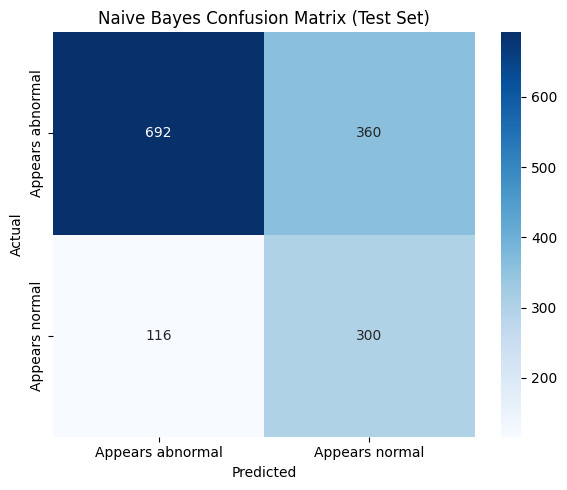


Final ResNet18 Test Loss: 0.4191 (CE: 0.2977, Dice: 0.5404), Final ResNet18 Test Accuracy: 0.8828

ResNet18 Test Precision (weighted): 0.8809
ResNet18 Test Recall (weighted):    0.8828
ResNet18 Test F1-score (weighted):  0.8793

ResNet18 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.89      0.95      0.92      1052
  Appears normal       0.85      0.71      0.77       416

        accuracy                           0.88      1468
       macro avg       0.87      0.83      0.85      1468
    weighted avg       0.88      0.88      0.88      1468



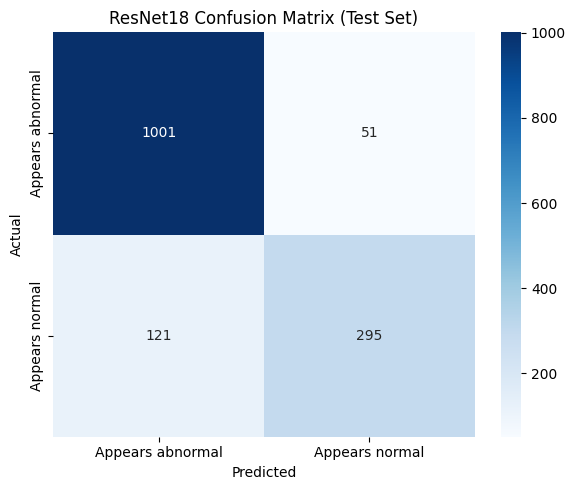

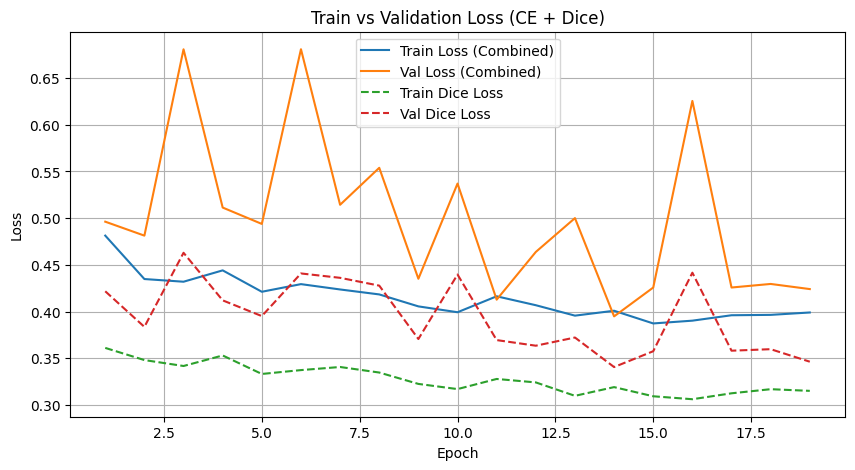

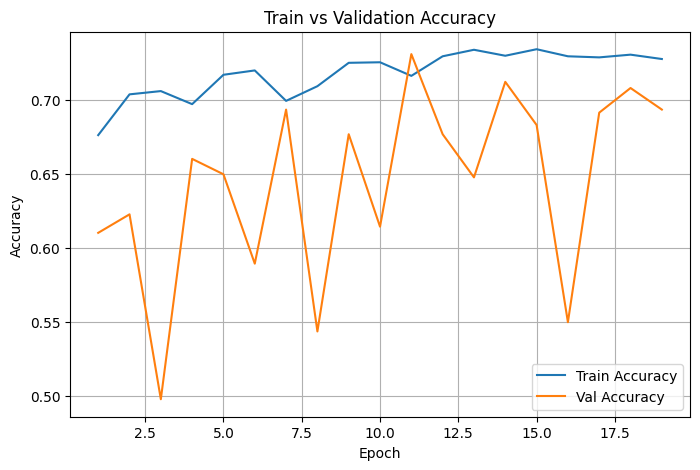


================ FINAL SUMMARY ================
ResNet18 Best Val Accuracy: 0.7312
ResNet18 Test Accuracy: 0.8828
ResNet18 Test Precision: 0.8809
ResNet18 Test Recall: 0.8828
ResNet18 Test F1-score: 0.8793
ResNet18 Test Dice Loss: 0.5404

--------------- Naive Bayes ----------------
Naive Bayes Val Accuracy: 0.5042
Naive Bayes Test Accuracy: 0.6757
Naive Bayes Test Precision: 0.7425
Naive Bayes Test Recall: 0.6757
Naive Bayes Test F1-score: 0.6912


In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.naive_bayes import GaussianNB
import seaborn as sns


# ============================================================
# Device configuration
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================

train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# Image transformations
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# Split train_dataset into train_subset + val_subset (85/15)
# ============================================================

val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Count the number of samples per class
# ============================================================

train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(train_targets)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================================
# Load pre-trained ResNet18 model
# ============================================================

resnet = models.resnet18(pretrained=True)

num_classes = len(train_dataset.classes)

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    num_classes
)

resnet = resnet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection
            + self.smooth
        ) / (
            union
            + self.smooth
        )

        dice_loss = (
            1. - dice_score.mean()
        )

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight


    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


optimizer = optim.Adam(
    resnet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate the model
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(
    model,
    loader
):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Resnet18_pcos.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# ResNet18 Training
# ============================================================

for epoch in range(max_epochs):

    resnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()


    train_accuracy = (
        correct_train / total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss / n_batches
    )

    train_ce = (
        running_ce / n_batches
    )

    train_dice = (
        running_dice / n_batches
    )


    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        resnet,
        val_loader
    )


    train_losses.append(
        train_loss
    )

    train_accs.append(
        train_accuracy
    )

    val_losses.append(
        val_loss
    )

    val_accs.append(
        val_accuracy
    )

    train_ce_losses.append(
        train_ce
    )

    train_dice_losses.append(
        train_dice
    )

    val_ce_losses.append(
        val_ce
    )

    val_dice_losses.append(
        val_dice
    )


    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # ========================================================
    # Early stopping logic
    # ========================================================

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            resnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best ResNet18 model
# ============================================================

best_resnet_model = models.resnet18(
    pretrained=False
)

best_resnet_model.fc = nn.Linear(
    best_resnet_model.fc.in_features,
    num_classes
)

best_resnet_model = best_resnet_model.to(device)

best_resnet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# NAIVE BAYES
# ResNet18 feature extraction + Gaussian Naive Bayes
# ============================================================

def extract_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # ResNet18 feature extractor
            x = model.conv1(images)
            x = model.bn1(x)
            x = model.relu(x)
            x = model.maxpool(x)

            x = model.layer1(x)
            x = model.layer2(x)
            x = model.layer3(x)
            x = model.layer4(x)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten features
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print(
    "\nExtracting ResNet18 features..."
)


train_features, train_labels = extract_features(
    best_resnet_model,
    train_loader
)


val_features, val_labels = extract_features(
    best_resnet_model,
    val_loader
)


test_features, test_labels = extract_features(
    best_resnet_model,
    test_loader
)


print(
    "Feature shape:",
    train_features.shape
)


# ============================================================
# Train Gaussian Naive Bayes
# ============================================================

nb_model = GaussianNB()


nb_model.fit(
    train_features,
    train_labels
)


# ============================================================
# Naive Bayes Validation
# ============================================================

nb_val_preds = nb_model.predict(
    val_features
)


nb_val_accuracy = np.mean(
    nb_val_preds == val_labels
)


print(
    f"\nNaive Bayes Validation Accuracy: "
    f"{nb_val_accuracy:.4f}"
)


# ============================================================
# Naive Bayes Test
# ============================================================

nb_test_preds = nb_model.predict(
    test_features
)


nb_test_accuracy = np.mean(
    nb_test_preds == test_labels
)


print(
    f"Naive Bayes Test Accuracy: "
    f"{nb_test_accuracy:.4f}"
)


# ============================================================
# Naive Bayes Metrics
# ============================================================

class_names = train_dataset.classes


nb_precision = precision_score(
    test_labels,
    nb_test_preds,
    average='weighted'
)


nb_recall = recall_score(
    test_labels,
    nb_test_preds,
    average='weighted'
)


nb_f1 = f1_score(
    test_labels,
    nb_test_preds,
    average='weighted'
)


print(
    f"\nNaive Bayes Test Precision: "
    f"{nb_precision:.4f}"
)


print(
    f"Naive Bayes Test Recall:    "
    f"{nb_recall:.4f}"
)


print(
    f"Naive Bayes Test F1-score:  "
    f"{nb_f1:.4f}"
)


# ============================================================
# Naive Bayes Classification Report
# ============================================================

print(
    "\nNaive Bayes Per-class report:"
)


print(
    classification_report(
        test_labels,
        nb_test_preds,
        target_names=class_names
    )
)


# ============================================================
# Naive Bayes Confusion Matrix
# ============================================================

nb_cm = confusion_matrix(
    test_labels,
    nb_test_preds
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    nb_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel('Predicted')

plt.ylabel('Actual')


plt.title(
    'Naive Bayes Confusion Matrix (Test Set)'
)


plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL RESNET18 TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_resnet_model,
    test_loader
)


print(
    f'\nFinal ResNet18 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final ResNet18 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# ResNet18 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_resnet_model,
    test_loader
)


class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)


recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)


f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)


print(
    f'\nResNet18 Test Precision (weighted): '
    f'{precision:.4f}'
)


print(
    f'ResNet18 Test Recall (weighted):    '
    f'{recall:.4f}'
)


print(
    f'ResNet18 Test F1-score (weighted):  '
    f'{f1:.4f}'
)


# ============================================================
# ResNet18 Classification Report
# ============================================================

print(
    '\nResNet18 Per-class report:'
)


print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# ResNet18 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel('Predicted')

plt.ylabel('Actual')


plt.title(
    'ResNet18 Confusion Matrix (Test Set)'
)


plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)


plt.figure(
    figsize=(10, 5)
)


plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)


plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)


plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)


plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)


plt.xlabel('Epoch')

plt.ylabel('Loss')


plt.title(
    'Train vs Validation Loss (CE + Dice)'
)


plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)


plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)


plt.xlabel('Epoch')

plt.ylabel('Accuracy')


plt.title(
    'Train vs Validation Accuracy'
)


plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)


print(
    f'ResNet18 Best Val Accuracy: '
    f'{best_accuracy:.4f}'
)


print(
    f'ResNet18 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


print(
    f'ResNet18 Test Precision: '
    f'{precision:.4f}'
)


print(
    f'ResNet18 Test Recall: '
    f'{recall:.4f}'
)


print(
    f'ResNet18 Test F1-score: '
    f'{f1:.4f}'
)


print(
    f'ResNet18 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n--------------- Naive Bayes ----------------'
)


print(
    f'Naive Bayes Val Accuracy: '
    f'{nb_val_accuracy:.4f}'
)


print(
    f'Naive Bayes Test Accuracy: '
    f'{nb_test_accuracy:.4f}'
)


print(
    f'Naive Bayes Test Precision: '
    f'{nb_precision:.4f}'
)


print(
    f'Naive Bayes Test Recall: '
    f'{nb_recall:.4f}'
)


print(
    f'Naive Bayes Test F1-score: '
    f'{nb_f1:.4f}'
)

# Adaboost

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:16<00:00,  2.66it/s]


Epoch [1/50] Train Loss: 0.5100 (CE: 0.6430, Dice: 0.3769), Train Acc: 0.6640 | Val Loss: 0.4944 (CE: 0.5882, Dice: 0.4006), Val Acc: 0.5750
  -> Saving best model (Val Accuracy: 0.5750)


100%|██████████| 43/43 [00:16<00:00,  2.66it/s]


Epoch [2/50] Train Loss: 0.4236 (CE: 0.5085, Dice: 0.3388), Train Acc: 0.7092 | Val Loss: 0.5446 (CE: 0.6888, Dice: 0.4004), Val Acc: 0.5833
  -> Saving best model (Val Accuracy: 0.5833)


100%|██████████| 43/43 [00:15<00:00,  2.70it/s]


...

Epoch [14/50] Train Loss: 0.3949 (CE: 0.4751, Dice: 0.3147), Train Acc: 0.7294 | Val Loss: 0.4716 (CE: 0.5646, Dice: 0.3785), Val Acc: 0.6479
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:15<00:00,  2.72it/s]


Epoch [15/50] Train Loss: 0.3979 (CE: 0.4785, Dice: 0.3173), Train Acc: 0.7335 | Val Loss: 0.5113 (CE: 0.6258, Dice: 0.3968), Val Acc: 0.5854
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 15. Best Val Accuracy: 0.7396


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



Extracting ResNet18 features...
Feature shape: (2720, 512)

AdaBoost Validation Accuracy: 0.6792
AdaBoost Test Accuracy: 0.8719

AdaBoost Test Precision: 0.8743
AdaBoost Test Recall:    0.8719
AdaBoost Test F1-score:  0.8729

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.92      0.90      0.91      1052
  Appears normal       0.76      0.80      0.78       416

        accuracy                           0.87      1468
       macro avg       0.84      0.85      0.84      1468
    weighted avg       0.87      0.87      0.87      1468



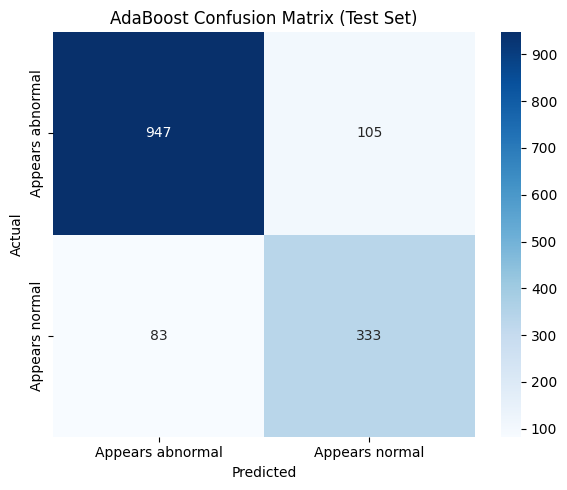


Final ResNet18 Test Loss: 0.4794 (CE: 0.4127, Dice: 0.5461), Final ResNet18 Test Accuracy: 0.8610

ResNet18 Test Precision (weighted): 0.8576
ResNet18 Test Recall (weighted):    0.8610
ResNet18 Test F1-score (weighted):  0.8568

ResNet18 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.88      0.94      0.91      1052
  Appears normal       0.81      0.67      0.73       416

        accuracy                           0.86      1468
       macro avg       0.84      0.80      0.82      1468
    weighted avg       0.86      0.86      0.86      1468



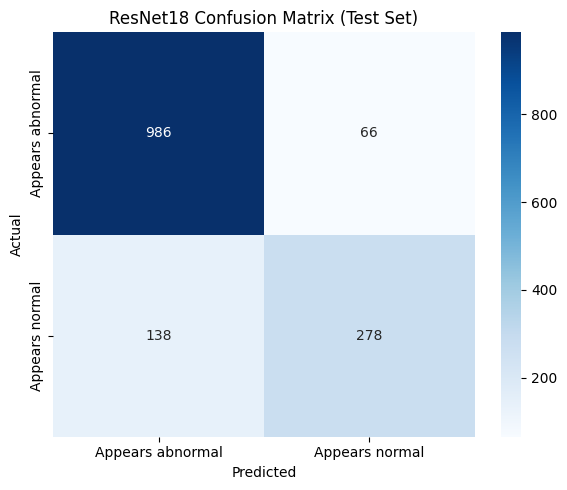

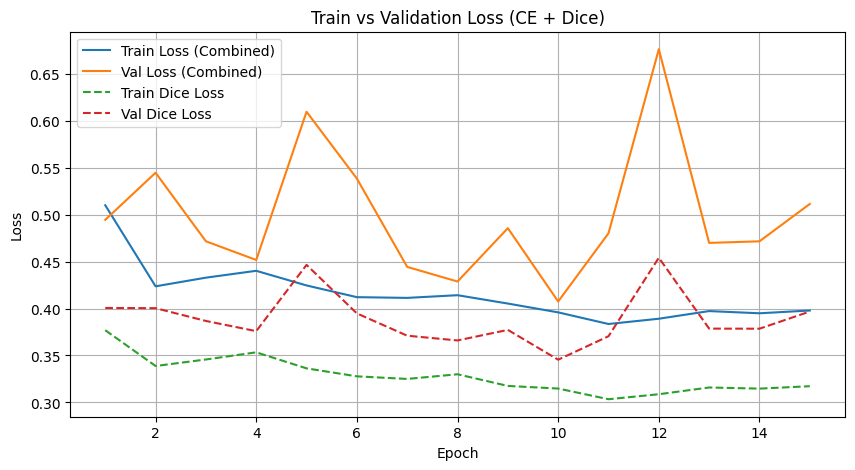

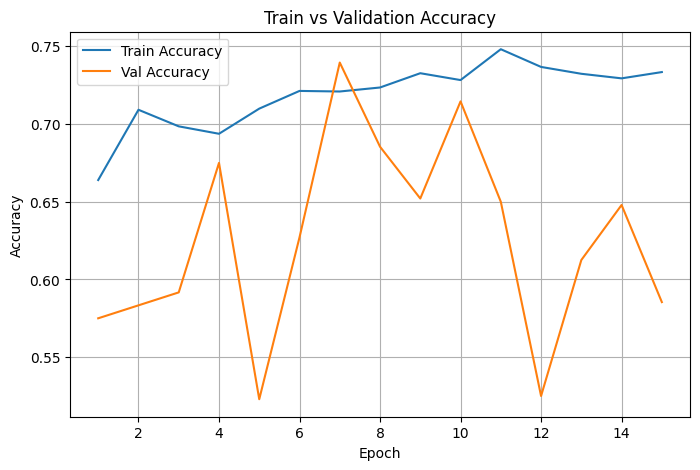


================ FINAL SUMMARY ================
ResNet18 Best Val Accuracy: 0.7396
ResNet18 Test Accuracy: 0.8610
ResNet18 Test Precision: 0.8576
ResNet18 Test Recall: 0.8610
ResNet18 Test F1-score: 0.8568
ResNet18 Test Dice Loss: 0.5461

--------------- AdaBoost ----------------
AdaBoost Val Accuracy: 0.6792
AdaBoost Test Accuracy: 0.8719
AdaBoost Test Precision: 0.8743
AdaBoost Test Recall: 0.8719
AdaBoost Test F1-score: 0.8729


In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

import seaborn as sns


# ============================================================
# Device configuration
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================

train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# ============================================================
# Image transformations
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# Split train_dataset into train_subset + val_subset (85/15)
# ============================================================

val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Count the number of samples per class
# ============================================================

train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(train_targets)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================================
# Load pre-trained ResNet18 model
# ============================================================

resnet = models.resnet18(pretrained=True)

num_classes = len(train_dataset.classes)

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    num_classes
)

resnet = resnet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        smooth=1e-6
    ):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth


    def forward(
        self,
        logits,
        targets
    ):

        probs = F.softmax(
            logits,
            dim=1
        )

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection
            + self.smooth
        ) / (
            union
            + self.smooth
        )

        dice_loss = (
            1. - dice_score.mean()
        )

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):

        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(
            num_classes
        )

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight


    def forward(
        self,
        logits,
        targets
    ):

        ce = self.ce_loss(
            logits,
            targets
        )

        dice = self.dice_loss(
            logits,
            targets
        )

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


optimizer = optim.Adam(
    resnet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate the model
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(
    model,
    loader
):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Resnet18_pcos.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# ResNet18 Training
# ============================================================

for epoch in range(max_epochs):

    resnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()


    train_accuracy = (
        correct_train / total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss / n_batches
    )

    train_ce = (
        running_ce / n_batches
    )

    train_dice = (
        running_dice / n_batches
    )


    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        resnet,
        val_loader
    )


    train_losses.append(
        train_loss
    )

    train_accs.append(
        train_accuracy
    )

    val_losses.append(
        val_loss
    )

    val_accs.append(
        val_accuracy
    )

    train_ce_losses.append(
        train_ce
    )

    train_dice_losses.append(
        train_dice
    )

    val_ce_losses.append(
        val_ce
    )

    val_dice_losses.append(
        val_dice
    )


    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # ========================================================
    # Early stopping logic
    # ========================================================

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            resnet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best ResNet18 model
# ============================================================

best_resnet_model = models.resnet18(
    pretrained=False
)

best_resnet_model.fc = nn.Linear(
    best_resnet_model.fc.in_features,
    num_classes
)

best_resnet_model = best_resnet_model.to(device)

best_resnet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# ADABOOST
# ResNet18 feature extraction + AdaBoost
# ============================================================

def extract_features(
    model,
    loader
):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # ResNet18 feature extractor
            x = model.conv1(images)
            x = model.bn1(x)
            x = model.relu(x)
            x = model.maxpool(x)

            x = model.layer1(x)
            x = model.layer2(x)
            x = model.layer3(x)
            x = model.layer4(x)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten features
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print(
    "\nExtracting ResNet18 features..."
)


train_features, train_labels = extract_features(
    best_resnet_model,
    train_loader
)


val_features, val_labels = extract_features(
    best_resnet_model,
    val_loader
)


test_features, test_labels = extract_features(
    best_resnet_model,
    test_loader
)


print(
    "Feature shape:",
    train_features.shape
)


# ============================================================
# Train AdaBoost
# ============================================================

base_estimator = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)


adaboost_model = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)


adaboost_model.fit(
    train_features,
    train_labels
)


# ============================================================
# AdaBoost Validation
# ============================================================

adaboost_val_preds = adaboost_model.predict(
    val_features
)


adaboost_val_accuracy = np.mean(
    adaboost_val_preds == val_labels
)


print(
    f"\nAdaBoost Validation Accuracy: "
    f"{adaboost_val_accuracy:.4f}"
)


# ============================================================
# AdaBoost Test
# ============================================================

adaboost_test_preds = adaboost_model.predict(
    test_features
)


adaboost_test_accuracy = np.mean(
    adaboost_test_preds == test_labels
)


print(
    f"AdaBoost Test Accuracy: "
    f"{adaboost_test_accuracy:.4f}"
)


# ============================================================
# AdaBoost Metrics
# ============================================================

class_names = train_dataset.classes


adaboost_precision = precision_score(
    test_labels,
    adaboost_test_preds,
    average='weighted'
)


adaboost_recall = recall_score(
    test_labels,
    adaboost_test_preds,
    average='weighted'
)


adaboost_f1 = f1_score(
    test_labels,
    adaboost_test_preds,
    average='weighted'
)


print(
    f"\nAdaBoost Test Precision: "
    f"{adaboost_precision:.4f}"
)


print(
    f"AdaBoost Test Recall:    "
    f"{adaboost_recall:.4f}"
)


print(
    f"AdaBoost Test F1-score:  "
    f"{adaboost_f1:.4f}"
)


# ============================================================
# AdaBoost Classification Report
# ============================================================

print(
    "\nAdaBoost Per-class report:"
)


print(
    classification_report(
        test_labels,
        adaboost_test_preds,
        target_names=class_names
    )
)


# ============================================================
# AdaBoost Confusion Matrix
# ============================================================

adaboost_cm = confusion_matrix(
    test_labels,
    adaboost_test_preds
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    adaboost_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel('Predicted')

plt.ylabel('Actual')


plt.title(
    'AdaBoost Confusion Matrix (Test Set)'
)


plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL RESNET18 TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_resnet_model,
    test_loader
)


print(
    f'\nFinal ResNet18 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final ResNet18 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# ResNet18 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_resnet_model,
    test_loader
)


class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)


recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)


f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)


print(
    f'\nResNet18 Test Precision (weighted): '
    f'{precision:.4f}'
)


print(
    f'ResNet18 Test Recall (weighted):    '
    f'{recall:.4f}'
)


print(
    f'ResNet18 Test F1-score (weighted):  '
    f'{f1:.4f}'
)


# ============================================================
# ResNet18 Classification Report
# ============================================================

print(
    '\nResNet18 Per-class report:'
)


print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# ResNet18 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)


plt.figure(
    figsize=(6, 5)
)


sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)


plt.xlabel('Predicted')

plt.ylabel('Actual')


plt.title(
    'ResNet18 Confusion Matrix (Test Set)'
)


plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)


plt.figure(
    figsize=(10, 5)
)


plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)


plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)


plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)


plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)


plt.xlabel('Epoch')

plt.ylabel('Loss')


plt.title(
    'Train vs Validation Loss (CE + Dice)'
)


plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)


plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)


plt.xlabel('Epoch')

plt.ylabel('Accuracy')


plt.title(
    'Train vs Validation Accuracy'
)


plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)


print(
    f'ResNet18 Best Val Accuracy: '
    f'{best_accuracy:.4f}'
)


print(
    f'ResNet18 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


print(
    f'ResNet18 Test Precision: '
    f'{precision:.4f}'
)


print(
    f'ResNet18 Test Recall: '
    f'{recall:.4f}'
)


print(
    f'ResNet18 Test F1-score: '
    f'{f1:.4f}'
)


print(
    f'ResNet18 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n--------------- AdaBoost ----------------'
)


print(
    f'AdaBoost Val Accuracy: '
    f'{adaboost_val_accuracy:.4f}'
)


print(
    f'AdaBoost Test Accuracy: '
    f'{adaboost_test_accuracy:.4f}'
)


print(
    f'AdaBoost Test Precision: '
    f'{adaboost_precision:.4f}'
)


print(
    f'AdaBoost Test Recall: '
    f'{adaboost_recall:.4f}'
)


print(
    f'AdaBoost Test F1-score: '
    f'{adaboost_f1:.4f}'
)